<a href="https://colab.research.google.com/github/HKozuka/IDX-Exchange-Data-Science/blob/main/04_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IDX Exchange - Feature Engineering, Decision Trees, & Random Forests**
Predicts `log_ClosePrice` for California single-family homes. Builds features, then compares a Decision Tree and a Random Forest using time-based cross-validation.

## 1. Setup

In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
import re, time
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

!pip install -q geopandas

pd.set_option('display.float_format', '{:,.2f}'.format)   # no scientific notation

BASE_PATH = '/content/drive/MyDrive/IDX Exchange Data Science Internship/Google Colab Notebooks/'
TARGET = 'log_ClosePrice'
CURRENT_YEAR = 2026

In [33]:
df_clean = pd.read_csv(f'{BASE_PATH}X_for_pre_feat_engin.csv').drop(columns=['Unnamed: 0'])
print(df_clean.shape)
df_clean.head()

(307722, 23)


,log_ClosePrice,CloseDate,ViewYN,WaterfrontYN,PoolPrivateYN,Stories,FireplaceYN,AssociationFeeFrequency,log_LivingArea,BathroomsTotalInteger,...,log_LotSizeSquareFeet,GarageSpaces,YearBuilt,UnparsedAddress,Latitude,Longitude,City,StateOrProvince,PostalCode,ListingContractDate
0,13.61,2024-01-05,False,False,False,2.00,False,NaN,7.59,4.00,...,8.89,2.00,"2,023.00",2811 C Avenue,32.66,-117.10,National City,CA,"91,950.00",2021-03-08
1,13.60,2024-01-05,False,False,False,2.00,False,NaN,7.59,4.00,...,8.89,2.00,"2,023.00",2812 C Avenue,32.66,-117.10,National City,CA,"91,950.00",2021-03-08
2,14.56,2024-01-02,True,False,False,2.00,True,NaN,8.23,4.00,...,9.33,3.00,"2,019.00",2054 Fixlini Street,35.28,-120.65,San Luis Obispo,CA,"93,401.00",2023-11-15
3,14.67,2024-01-31,True,False,False,1.00,True,NaN,7.80,3.00,...,9.07,3.00,"1,985.00",3114 Rasmus Circle,37.33,-121.78,San Jose,CA,"95,148.00",2024-01-31
4,13.87,2024-01-16,True,False,False,1.00,True,NaN,7.56,3.00,...,9.48,2.00,"1,965.00",3707 Primavera Avenue,34.11,-118.22,Los Angeles,CA,"90,065.00",2023-12-07


## 2. Feature Engineering
Features are built on `df_clean` (training data). Section 3 applies the same steps to the test set.

### 2.1 Property Age
Years since built, plus a log version.

In [34]:
def add_property_age(df):
    df = df.copy()
    df['PropertyAge'] = (CURRENT_YEAR - df['YearBuilt']).astype(float)
    df['log_PropertyAge'] = np.log1p(df['PropertyAge'])
    return df

df_clean = add_property_age(df_clean)
df_clean[['YearBuilt', 'PropertyAge', 'log_PropertyAge']].head()

,YearBuilt,PropertyAge,log_PropertyAge
0,"2,023.00",3.00,1.39
1,"2,023.00",3.00,1.39
2,"2,019.00",7.00,2.08
3,"1,985.00",41.00,3.74
4,"1,965.00",61.00,4.13


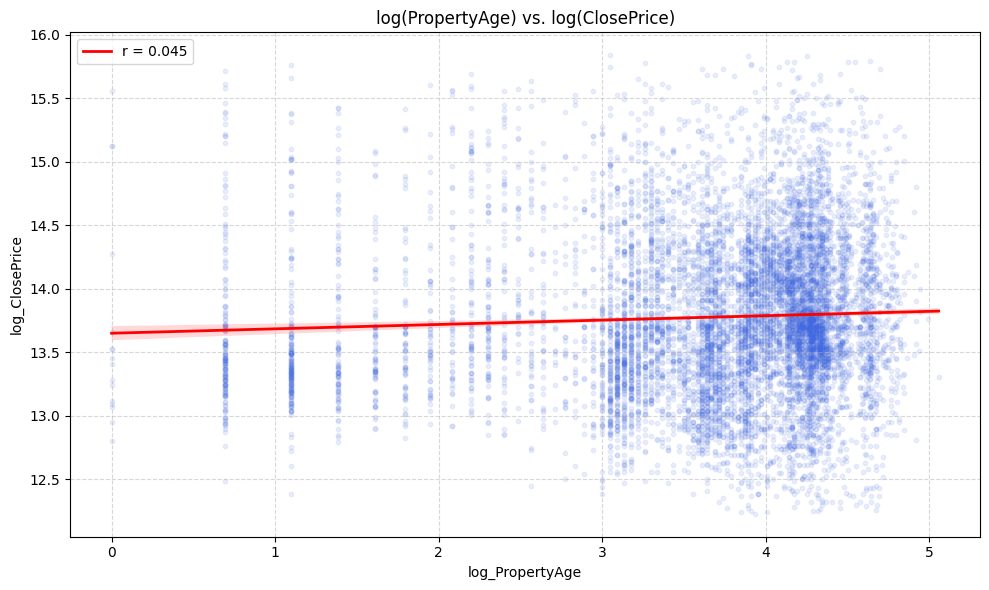

In [35]:
plot_data = df_clean[['log_PropertyAge', TARGET]].dropna()
r = plot_data.corr().iloc[0, 1]

plt.figure(figsize=(10, 6))
sns.regplot(data=plot_data.sample(10_000, random_state=42), x='log_PropertyAge', y=TARGET,
            scatter_kws={'alpha': 0.1, 's': 10, 'color': 'royalblue'},
            line_kws={'color': 'red', 'linewidth': 2, 'label': f'r = {r:.3f}'})
plt.title('log(PropertyAge) vs. log(ClosePrice)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 2.2 Listing Seasonality
`ListingContractDate` (when the seller signed with their broker) is mapped onto a circle, so December 31 and January 1 end up next to each other instead of 364 days apart.

$$\text{ListSeason_sin} = \sin\left(2\pi \cdot \frac{\text{day of year} - 1}{\text{days in year}}\right) \qquad \text{ListSeason_cos} = \cos\left(2\pi \cdot \frac{\text{day of year} - 1}{\text{days in year}}\right)$$

Both are needed: sine alone gives the same value for two different times of year.

In [36]:
def add_seasonality(df):
    df = df.copy()
    listed = pd.to_datetime(df['ListingContractDate'], errors='coerce')
    days_in_year = np.where(listed.dt.is_leap_year, 366, 365)
    angle = 2 * np.pi * (listed.dt.dayofyear - 1) / days_in_year
    df['ListSeason_sin'] = np.sin(angle)
    df['ListSeason_cos'] = np.cos(angle)
    return df

df_clean = add_seasonality(df_clean)
df_clean[['ListingContractDate', 'ListSeason_sin', 'ListSeason_cos']].head()

,ListingContractDate,ListSeason_sin,ListSeason_cos
0,2021-03-08,0.91,0.42
1,2021-03-08,0.91,0.42
2,2023-11-15,-0.72,0.69
3,2024-01-31,0.49,0.87
4,2023-12-07,-0.42,0.91


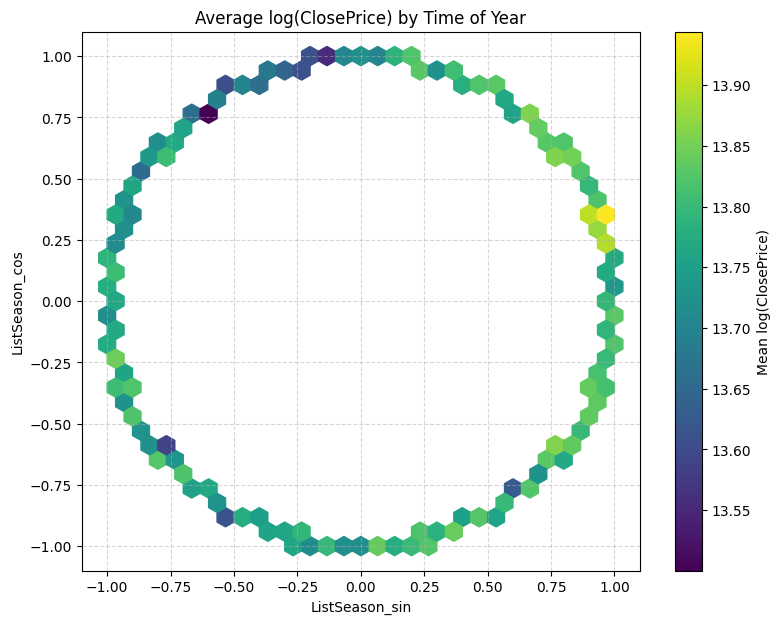

In [37]:
sample = df_clean[['ListSeason_sin', 'ListSeason_cos', TARGET]].dropna().sample(30_000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 7))
hb = ax.hexbin(sample['ListSeason_sin'], sample['ListSeason_cos'], C=sample[TARGET],
               gridsize=30, cmap='viridis', reduce_C_function=np.mean, mincnt=5)
ax.set_title('Average log(ClosePrice) by Time of Year')
ax.set_xlabel('ListSeason_sin')
ax.set_ylabel('ListSeason_cos')
ax.grid(True, linestyle='--', alpha=0.5)
fig.colorbar(hb, ax=ax, label='Mean log(ClosePrice)')
plt.show()

### 2.3 School Score
Uses CAASPP state test results directly (the source behind GreatSchools ratings in CA).
1. Score each school: average % of students meeting or exceeding standard in ELA and Math.
2. Match each listing to its nearest elementary, middle, and high school.
3. Non-CA listings are dropped.

In [38]:
SCHOOLS_FILE = f'{BASE_PATH}pubschls.txt'             # CA Dept. of Education school directory
CAASPP_FILE = f'{BASE_PATH}sb_ca2025_all_csv_v1.txt'  # 2025 CAASPP results, ELA and Math
EXCLUDE_CHARTERS = True

def load_school_ratings():
    # School directory: locations and levels
    sch = pd.read_csv(SCHOOLS_FILE, sep='\t', dtype=str, encoding='latin-1')
    sch = sch[(sch['StatusType'] == 'Active') &
              sch['EILCode'].isin(['ELEM', 'INTMIDJR', 'HS'])]
    if EXCLUDE_CHARTERS:
        sch = sch[sch['Charter'] != 'Y']
    sch[['Latitude', 'Longitude']] = sch[['Latitude', 'Longitude']].apply(
        pd.to_numeric, errors='coerce')
    sch = sch.dropna(subset=['Latitude', 'Longitude'])

    # Test results: read in chunks, keep all students, all grades, ELA and math
    chunks = []
    for ch in pd.read_csv(CAASPP_FILE, sep='^', dtype=str, encoding='latin-1',
                          chunksize=500_000):
        ch.columns = [re.sub(r'[^a-z]', '', c.lower()) for c in ch.columns]
        ch = ch[(ch['studentgroupid'] == '1') &
                (ch['grade'] == '13') &
                ch['testid'].isin(['1', '2'])]
        chunks.append(ch)
    cs = pd.concat(chunks, ignore_index=True)

    # Build CDS code and average ELA and math
    cs['CDSCode'] = (cs['countycode'].str.zfill(2) +
                     cs['districtcode'].str.zfill(5) +
                     cs['schoolcode'].str.zfill(7))
    cs = cs[~cs['CDSCode'].str.endswith('0000000')]
    cs['pct'] = pd.to_numeric(cs['percentagestandardmetandabove'], errors='coerce')
    ratings = cs.groupby('CDSCode')['pct'].mean().rename('SchoolRating')

    sch = sch.merge(ratings, on='CDSCode', how='inner').dropna(subset=['SchoolRating'])
    print(sch['EILCode'].value_counts())
    return sch

schools = load_school_ratings()

EILCode
ELEM        5213
HS          1533
INTMIDJR    1195
Name: count, dtype: int64


In [39]:
def filter_ca(df):
    """Keep listings with California coordinates (or missing coordinates)."""
    df = df.copy()
    df[['Latitude', 'Longitude']] = df[['Latitude', 'Longitude']].apply(pd.to_numeric, errors='coerce')
    in_ca = df['Latitude'].between(32.5, 42.1) & df['Longitude'].between(-124.5, -114.1)
    missing = df['Latitude'].isna() | df['Longitude'].isna()
    print('Rows outside California dropped:', (~in_ca & ~missing).sum())
    return df[in_ca | missing].reset_index(drop=True)

df_clean = filter_ca(df_clean)

Rows outside California dropped: 74


In [40]:
def add_school_ratings(df, schools):
    """Rating and distance (m) of the nearest elementary, middle, and high school."""
    df = df.copy()
    has = df['Latitude'].notna() & df['Longitude'].notna()
    props = gpd.GeoDataFrame(
        index=df.index[has],
        geometry=gpd.points_from_xy(df.loc[has, 'Longitude'], df.loc[has, 'Latitude']),
        crs='EPSG:4326').to_crs('EPSG:3310')
    sg = gpd.GeoDataFrame(
        schools[['EILCode', 'SchoolRating']],
        geometry=gpd.points_from_xy(schools['Longitude'], schools['Latitude']),
        crs='EPSG:4326').to_crs('EPSG:3310')

    for level, name in [('ELEM', 'Elem'), ('INTMIDJR', 'Middle'), ('HS', 'High')]:
        lvl = sg.loc[sg['EILCode'] == level, ['SchoolRating', 'geometry']]
        j = gpd.sjoin_nearest(props, lvl, how='left', distance_col='dist')
        j = j[~j.index.duplicated()]
        df[f'{name}SchoolRating'] = j['SchoolRating']
        df[f'{name}SchoolDist_m'] = j['dist']

    df['SchoolRating_missing'] = df['ElemSchoolRating'].isna().astype(int)
    return df

df_clean = add_school_ratings(df_clean, schools)
df_clean.filter(like='School').describe()

,ElemSchoolRating,ElemSchoolDist_m,MiddleSchoolRating,MiddleSchoolDist_m,HighSchoolRating,HighSchoolDist_m,SchoolRating_missing
count,"307,648.00","307,648.00","307,648.00","307,648.00","307,648.00","307,648.00","307,648.00"
mean,47.53,"1,245.51",42.07,"2,738.21",39.55,"2,649.51",0.00
std,20.12,"1,558.67",19.47,"3,974.07",22.26,"2,787.41",0.00
min,0.00,0.83,0.00,6.95,0.00,0.35,0.00
25%,30.98,514.06,26.00,"1,152.36",24.05,"1,241.92",0.00
50%,45.98,837.35,39.45,"1,871.12",39.65,"1,958.78",0.00
75%,63.54,"1,410.66",57.71,"3,019.84",57.20,"3,093.39",0.00
max,95.75,"105,406.91",92.41,"130,749.49",98.59,"130,749.49",0.00


#### Collinearity check

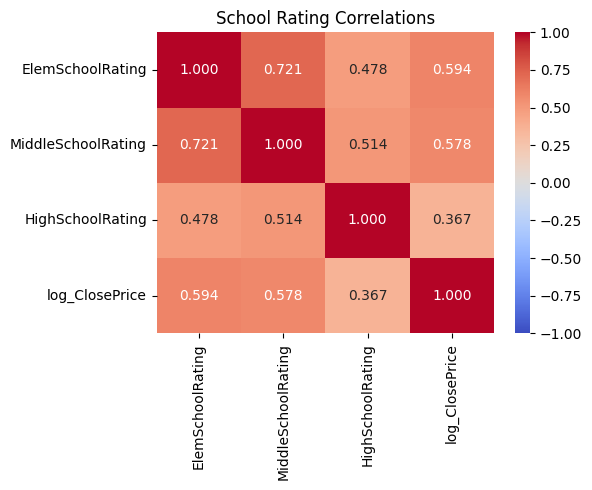

In [41]:
SCHOOL_COLS = ['ElemSchoolRating', 'MiddleSchoolRating', 'HighSchoolRating']

plt.figure(figsize=(6, 5))
sns.heatmap(df_clean[SCHOOL_COLS + [TARGET]].corr(), annot=True, fmt='.3f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('School Rating Correlations')
plt.tight_layout()
plt.show()

#### Combine into one SchoolScore
The three ratings are highly correlated, so `SchoolScore` is their average (0 to 100 scale).

In [42]:
def add_school_score(df):
    df = df.copy()
    df['SchoolScore'] = df[SCHOOL_COLS].mean(axis=1)
    return df.drop(columns=SCHOOL_COLS)

df_clean = add_school_score(df_clean)

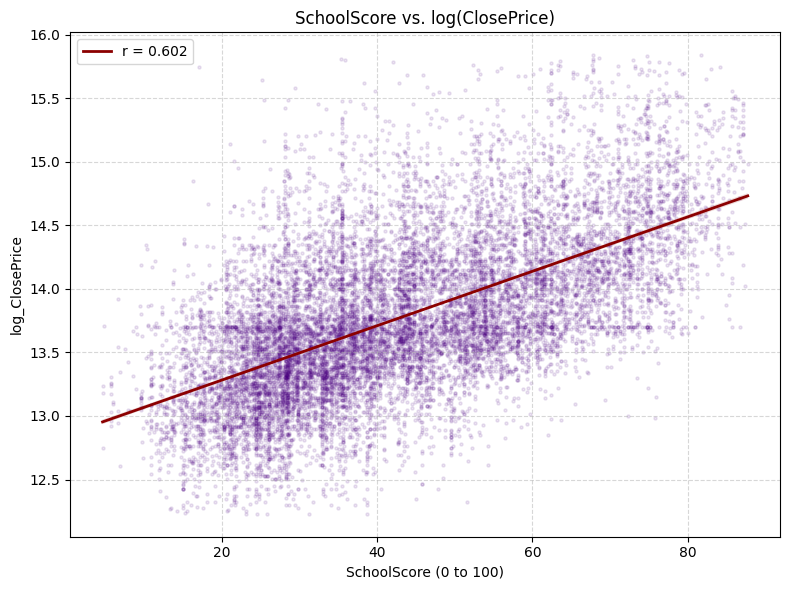

In [43]:
plot_data = df_clean[['SchoolScore', TARGET]].dropna()
r = plot_data.corr().iloc[0, 1]

plt.figure(figsize=(8, 6))
sns.regplot(data=plot_data.sample(15_000, random_state=42), x='SchoolScore', y=TARGET,
            scatter_kws={'alpha': 0.1, 's': 5, 'color': 'indigo'},
            line_kws={'color': 'darkred', 'linewidth': 2, 'label': f'r = {r:.3f}'})
plt.title('SchoolScore vs. log(ClosePrice)')
plt.xlabel('SchoolScore (0 to 100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 2.4 Bed/Bath Ratio

In [44]:
def add_bed_bath_ratio(df):
    df = df.copy()
    ratio = df['BedroomsTotal'] / df['BathroomsTotalInteger']
    df['BedBathRatio'] = ratio.replace([np.inf, -np.inf], np.nan)   # 0 baths
    return df

df_clean = add_bed_bath_ratio(df_clean)

### 2.5 GeoCluster
K-Means (k = 20) on latitude and longitude groups listings into regions. Missing coordinates get -1.

In [45]:
kmeans = KMeans(n_clusters=20, random_state=42, n_init=10)
kmeans.fit(df_clean[['Latitude', 'Longitude']].dropna())

def add_geocluster(df):
    """Nearest K-Means region for each listing (-1 if coordinates are missing)."""
    df = df.copy()
    has = df['Latitude'].notna() & df['Longitude'].notna()
    df['GeoCluster'] = -1
    df.loc[has, 'GeoCluster'] = kmeans.predict(df.loc[has, ['Latitude', 'Longitude']])
    return df

df_clean = add_geocluster(df_clean)
df_clean['GeoCluster'].value_counts()

,count
GeoCluster,
5,39767
1,37245
11,29502
19,27533
14,23067
12,22254
15,18564
2,17354
6,14968


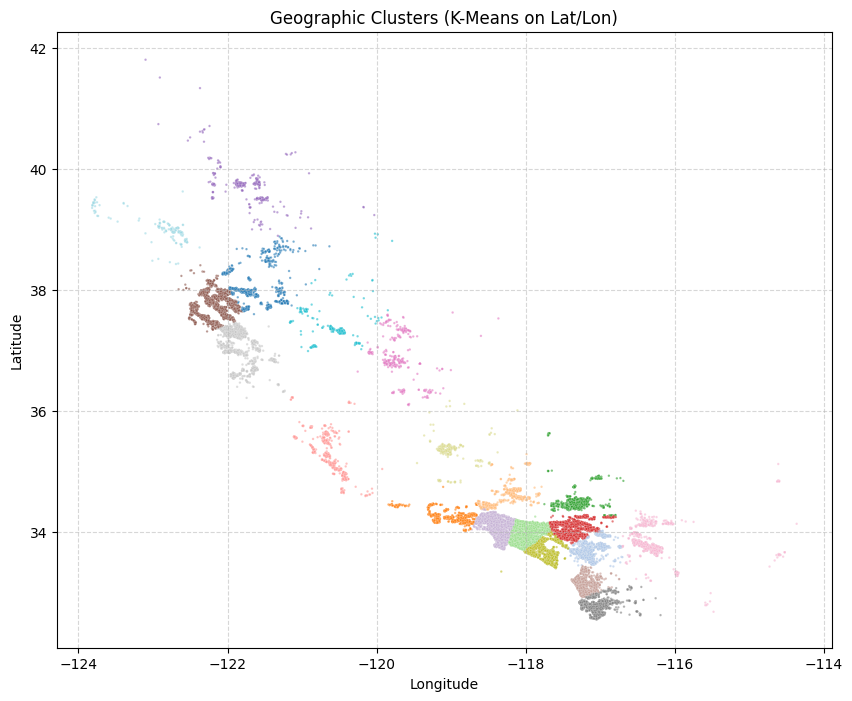

In [46]:
plot_sample = df_clean.sample(30_000, random_state=42)

plt.figure(figsize=(10, 8))
sns.scatterplot(data=plot_sample, x='Longitude', y='Latitude',
                hue=plot_sample['GeoCluster'].astype(str),   # discrete colors
                palette='tab20', s=3, alpha=0.6, legend=False)
plt.title('Geographic Clusters (K-Means on Lat/Lon)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2.6 Amenity Flags and Monthly HOA
- View, Waterfront, Pool, and Fireplace are True/False, so they're converted to 1/0 (the model only uses numeric columns).
- `HOA_Monthly` puts monthly, quarterly, semiannual, and annual fees on one monthly scale. `HasHOA` flags any fee.

In [47]:
AMENITY_COLS = ['ViewYN', 'WaterfrontYN', 'PoolPrivateYN', 'FireplaceYN']
HOA_PER_MONTH = {'Monthly': 1, 'Quarterly': 1/3, 'SemiAnnually': 1/6, 'Annually': 1/12}

def add_amenity_hoa(df):
    df = df.copy()
    for c in AMENITY_COLS:
        s = df[c]
        if s.dtype == object:                       # CSVs can load these as text
            s = s.map({'True': 1, 'False': 0, True: 1, False: 0})
        df[c] = s.astype(float)

    # A fee with no frequency listed is treated as monthly (the most common case)
    per_month = df['AssociationFeeFrequency'].map(HOA_PER_MONTH).fillna(1)
    df['HOA_Monthly'] = df['AssociationFee'].fillna(0) * per_month
    df['HasHOA'] = (df['HOA_Monthly'] > 0).astype(int)
    return df

df_clean = add_amenity_hoa(df_clean)
df_clean[AMENITY_COLS + ['HOA_Monthly', 'HasHOA']].describe()

,ViewYN,WaterfrontYN,PoolPrivateYN,FireplaceYN,HOA_Monthly,HasHOA
count,"307,648.00","307,648.00","307,648.00","307,648.00","307,648.00","307,648.00"
mean,0.55,0.00,0.15,0.73,54.28,0.25
std,0.50,0.02,0.35,0.45,140.68,0.43
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,0.00
50%,1.00,0.00,0.00,1.00,0.00,0.00
75%,1.00,0.00,0.00,1.00,6.67,1.00
max,1.00,1.00,1.00,1.00,"5,553.00",1.00


### 2.7 Size Ratios
- `LotCoverage`: living area ÷ lot size (dense infill vs. large lots).
- `SqftPerBedroom`: living area ÷ bedrooms (spacious vs. tight layouts).

In [48]:
def add_size_ratios(df):
    df = df.copy()
    living = np.expm1(df['log_LivingArea'])
    lot = np.expm1(df['log_LotSizeSquareFeet'])
    df['LotCoverage'] = (living / lot).replace([np.inf, -np.inf], np.nan)
    df['SqftPerBedroom'] = (living / df['BedroomsTotal']).replace([np.inf, -np.inf], np.nan)
    return df

df_clean = add_size_ratios(df_clean)
df_clean[['LotCoverage', 'SqftPerBedroom']].describe()

,LotCoverage,SqftPerBedroom
count,"307,487.00","307,648.00"
mean,12.10,577.69
std,608.22,194.18
min,0.00,91.75
25%,0.17,445.50
50%,0.24,539.50
75%,0.33,662.67
max,"238,600.00","8,050.00"


### 2.8 Recent Neighborhood Prices
Average log price per sq ft of homes in the same ZIP that **closed in the 6 months before the listing month**. Falls back to GeoCluster when a ZIP has fewer than 5 sales.
- Only looks backward in time, so it never uses a listing's own price. This replaces the old Price per Sq Ft feature, which leaked the target.
- `Nbhd_logprice_est`: neighborhood price per sq ft + this home's log living area (a rough comps estimate).
- `Zip_sales_6m`: number of sales in the window (market activity).

In [49]:
def prior_price_level(target, history, group_col, window=6, min_sales=5):
    """Mean log price per sqft of history sales in the same group that closed in the
    `window` calendar months BEFORE each target row's listing month."""
    h = pd.DataFrame({
        'g': pd.to_numeric(history[group_col], errors='coerce').values,
        'm': pd.to_datetime(history['CloseDate']).dt.to_period('M').values,
        'ppsf': (history['log_ClosePrice'] - history['log_LivingArea']).values,
    }).dropna()
    t_group = pd.to_numeric(target[group_col], errors='coerce')
    t_month = pd.to_datetime(target['ListingContractDate'], errors='coerce').dt.to_period('M')

    months = pd.period_range(min(h['m'].min(), t_month.min()), max(h['m'].max(), t_month.max()), freq='M')
    sums = h.pivot_table(index='m', columns='g', values='ppsf', aggfunc='sum').reindex(months).fillna(0)
    cnts = h.pivot_table(index='m', columns='g', values='ppsf', aggfunc='count').reindex(months).fillna(0)

    # shift(1): the window ends the month BEFORE the listing month
    roll_sum = sums.rolling(window, min_periods=1).sum().shift(1)
    roll_cnt = cnts.rolling(window, min_periods=1).sum().shift(1)
    level = (roll_sum / roll_cnt).where(roll_cnt >= min_sales)

    key = pd.MultiIndex.from_arrays([t_month, t_group])
    return (level.stack().reindex(key).values,
            roll_cnt.stack().reindex(key).values)

def add_neighborhood_prices(df, history):
    df = df.copy()
    hist = history.copy()
    # GeoCluster -1 means "missing coordinates", not a real neighborhood
    hist['GeoCluster'] = hist['GeoCluster'].replace(-1, np.nan)
    target = df.assign(GeoCluster=df['GeoCluster'].replace(-1, np.nan))

    zip_lvl, zip_n = prior_price_level(target, hist, 'PostalCode')
    clu_lvl, _ = prior_price_level(target, hist, 'GeoCluster')

    df['Zip_ppsf_6m'] = zip_lvl
    df['Zip_sales_6m'] = zip_n
    df['Nbhd_ppsf_6m'] = np.where(np.isnan(zip_lvl), clu_lvl, zip_lvl)   # ZIP first, GeoCluster fallback
    df['Nbhd_logprice_est'] = df['Nbhd_ppsf_6m'] + df['log_LivingArea']
    return df

df_clean = add_neighborhood_prices(df_clean, history=df_clean)

new_cols = ['Zip_ppsf_6m', 'Zip_sales_6m', 'Nbhd_ppsf_6m', 'Nbhd_logprice_est']
print('Share of rows with a neighborhood price:', f"{df_clean['Nbhd_ppsf_6m'].notna().mean():.1%}")
print('Correlation of Nbhd_logprice_est with log_ClosePrice:',
      f"{df_clean['Nbhd_logprice_est'].corr(df_clean['log_ClosePrice']):.3f}")
df_clean[new_cols].describe()

Share of rows with a neighborhood price: 89.7%
Correlation of Nbhd_logprice_est with log_ClosePrice: 0.899


,Zip_ppsf_6m,Zip_sales_6m,Nbhd_ppsf_6m,Nbhd_logprice_est
count,"270,699.00","307,646.00","276,093.00","276,093.00"
mean,6.26,93.59,6.26,13.78
std,0.45,83.76,0.45,0.64
min,5.11,0.00,5.11,11.23
25%,5.90,32.00,5.89,13.33
50%,6.30,77.00,6.29,13.75
75%,6.58,131.00,6.57,14.20
max,7.85,555.00,7.85,16.46


### 2.9 Comparable Sales (Comps)
For each listing, the 10 nearest homes that **closed in the 12 months before the listing month**. Tighter than ZIP, and closer to how appraisers price a home.
- `Comp_ppsf`: median log price per sq ft of the comps.
- `Comp_logprice_est`: comps' price per sq ft applied to this home's size.
- `Comp_size_diff`: this home's log living area minus the comps' median (bigger or smaller than its neighbors).
- `Comp_dist_km`: average distance to the comps (dense vs. rural areas).

In [53]:
from sklearn.neighbors import BallTree

EARTH_RADIUS_KM = 6371.0

def add_comps(df, history, k=10, lookback_months=12):
    """k nearest history sales that closed in the lookback window BEFORE each listing month."""
    df = df.copy()
    h = history[['Latitude', 'Longitude', 'CloseDate', TARGET, 'log_LivingArea']].dropna().copy()
    h['m'] = pd.to_datetime(h['CloseDate']).dt.to_period('M')
    h['ppsf'] = h[TARGET] - h['log_LivingArea']

    list_m = pd.to_datetime(df['ListingContractDate'], errors='coerce').dt.to_period('M')
    has = (df['Latitude'].notna() & df['Longitude'].notna() & list_m.notna()).values
    out = {c: np.full(len(df), np.nan) for c in ['Comp_ppsf', 'Comp_size', 'Comp_dist_km']}

    for m in sorted(list_m[has].unique()):
        pool = h[(h['m'] < m) & (h['m'] >= m - lookback_months)]
        if len(pool) < k:
            continue
        tree = BallTree(np.radians(pool[['Latitude', 'Longitude']].values), metric='haversine')
        rows = np.where(has & (list_m == m).values)[0]
        dist, idx = tree.query(np.radians(df.iloc[rows][['Latitude', 'Longitude']].values), k=k)
        out['Comp_ppsf'][rows] = np.median(pool['ppsf'].values[idx], axis=1)
        out['Comp_size'][rows] = np.median(pool['log_LivingArea'].values[idx], axis=1)
        out['Comp_dist_km'][rows] = dist.mean(axis=1) * EARTH_RADIUS_KM

    df['Comp_ppsf'] = out['Comp_ppsf']
    df['Comp_logprice_est'] = out['Comp_ppsf'] + df['log_LivingArea']
    df['Comp_size_diff'] = df['log_LivingArea'] - out['Comp_size']
    df['Comp_dist_km'] = out['Comp_dist_km']
    return df

t0 = time.time()
df_clean = add_comps(df_clean, history=df_clean)
print(f"{time.time() - t0:.0f}s, coverage: {df_clean['Comp_ppsf'].notna().mean():.1%}")
print(f"Correlation of Comp_logprice_est with {TARGET}: {df_clean['Comp_logprice_est'].corr(df_clean[TARGET]):.3f}")

49s, coverage: 89.7%
Correlation of Comp_logprice_est with log_ClosePrice: 0.906


### 2.10 Distance to Coast
Distance in km to the nearest ocean coastline (Natural Earth 1:10m coastline). One of the strongest price signals in California.

In [57]:
COAST_URLS = ['https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip',
              'https://naciscdn.org/naturalearth/10m/physical/ne_10m_coastline.zip']

for url in COAST_URLS:
    coast = gpd.read_file(url)

coast = coast.cx[-126:-113, 31.5:43].to_crs('EPSG:3310')[['geometry']]   # CA area, meters

def add_coast_distance(df):
    df = df.copy()
    has = df['Latitude'].notna() & df['Longitude'].notna()
    pts = gpd.GeoDataFrame(
        index=df.index[has],
        geometry=gpd.points_from_xy(df.loc[has, 'Longitude'], df.loc[has, 'Latitude']),
        crs='EPSG:4326').to_crs('EPSG:3310')
    j = gpd.sjoin_nearest(pts, coast, how='left', distance_col='dist')
    j = j[~j.index.duplicated()]
    df['CoastDist_km'] = j['dist'] / 1000
    return df

t0 = time.time()
df_clean = add_coast_distance(df_clean)


## 3. Training, Validation, and Test Data
- **Training:** `df_clean`. Validation folds 1 to 5 are time-ordered slices of it.
- **Validation (expanding window):** for each fold, train on everything that closed before it, then score on it. The model never sees the rows it's scored on.
- **Test:** same features, scored once at the end.

In [58]:
df_test = pd.read_csv(f'{BASE_PATH}test_dataset.csv').drop(columns=['Unnamed: 0'], errors='ignore')
folds_raw = {k: pd.read_csv(f'{BASE_PATH}validation_fold_{k}.csv').drop(columns=['Unnamed: 0'], errors='ignore')
             for k in range(1, 6)}

def make_key(d):
    """Address + close date + listing date, used to find each fold's rows in df_clean."""
    return (d['UnparsedAddress'].astype(str) + '|' +
            pd.to_datetime(d['CloseDate']).dt.strftime('%Y-%m-%d') + '|' +
            pd.to_datetime(d['ListingContractDate']).dt.strftime('%Y-%m-%d'))

clean_key = make_key(df_clean)
fold_masks = {}
for k, f in folds_raw.items():
    fold_masks[k] = clean_key.isin(set(make_key(f))).values
    print(f"fold {k}: {fold_masks[k].sum():,} of {len(f):,} rows matched "
          f"(closed {f['CloseDate'].min()} to {f['CloseDate'].max()})")

fold 1: 49,213 of 49,219 rows matched (closed 2024-05-17 to 2024-09-13)
fold 2: 49,205 of 49,219 rows matched (closed 2024-09-13 to 2025-02-06)
fold 3: 49,206 of 49,219 rows matched (closed 2025-02-06 to 2025-06-20)
fold 4: 49,209 of 49,219 rows matched (closed 2025-06-20 to 2025-10-28)
fold 5: 49,203 of 49,219 rows matched (closed 2025-10-28 to 2026-03-31)


In [59]:
def build_features(df, history):
    """Run every Section 2 step on a new split. Neighborhood prices come from `history` only."""
    df = filter_ca(df)
    df = add_property_age(df)
    df = add_seasonality(df)
    df = add_school_score(add_school_ratings(df, schools))
    df = add_bed_bath_ratio(df)
    df = add_geocluster(df)
    df = add_amenity_hoa(df)
    df = add_size_ratios(df)
    df = add_neighborhood_prices(df, history)
    df = add_comps(df, history)
    return add_coast_distance(df)

test = build_features(df_test, history=df_clean)

Rows outside California dropped: 4


In [60]:
DROP = [TARGET, 'CloseDate', 'AssociationFee']   # AssociationFee is replaced by HOA_Monthly

def to_xy(df, feature_cols=None):
    """Numeric feature matrix and target. Pass feature_cols to match the training columns."""
    X = df.drop(columns=[c for c in DROP if c in df.columns])
    X = X.select_dtypes(include='number').astype(float).replace([np.inf, -np.inf], np.nan)
    if feature_cols is not None:
        missing = set(feature_cols) - set(X.columns)
        if missing:
            print('WARNING, missing columns:', missing)
        X = X.reindex(columns=feature_cols)
    return X, df[TARGET]

X_all, y_all = to_xy(df_clean)
FEATURES = list(X_all.columns)
X_test, y_test = to_xy(test, FEATURES)

# Expanding window: train on rows that closed before each fold, validate on the fold
close_dates = pd.to_datetime(df_clean['CloseDate'])
cv_splits = []
for k, val_mask in fold_masks.items():
    train_mask = (close_dates < close_dates[val_mask].min()).values & ~val_mask
    cv_splits.append((k, train_mask, val_mask))
    print(f"fold {k}: train {train_mask.sum():,}, validate {val_mask.sum():,}")
FOLD_COLS = [f'fold {k}' for k in fold_masks]

print(f"\n{len(FEATURES)} features: {FEATURES}")
print('Test:', X_test.shape)

def cv_score(make_model):
    """R2 on each validation fold, training on its expanding window."""
    scores = {}
    for k, tr, va in cv_splits:
        model = make_model().fit(X_all[tr], y_all[tr])
        scores[f'fold {k}'] = r2_score(y_all[va], model.predict(X_all[va]))
    return scores

def tune(make_model, depths):
    """Cross-validate each max_depth; returns one row per depth."""
    rows = []
    for depth in depths:
        t0 = time.time()
        rows.append({'max_depth': depth, **cv_score(lambda: make_model(depth))})
        print(f"max_depth={depth}: {time.time() - t0:.0f}s")
    results = pd.DataFrame(rows)
    results['mean_R2'] = results[FOLD_COLS].mean(axis=1)
    return results

def best_depth(results):
    d = results.loc[results['mean_R2'].idxmax(), 'max_depth']
    return None if pd.isna(d) else int(d)

fold 1: train 48,810, validate 49,213
fold 2: train 98,228, validate 49,205
fold 3: train 147,305, validate 49,206
fold 4: train 196,360, validate 49,209
fold 5: train 245,586, validate 49,203

39 features: ['ViewYN', 'WaterfrontYN', 'PoolPrivateYN', 'Stories', 'FireplaceYN', 'log_LivingArea', 'BathroomsTotalInteger', 'log_BuildingAreaTotal', 'BedroomsTotal', 'log_LotSizeSquareFeet', 'GarageSpaces', 'YearBuilt', 'Latitude', 'Longitude', 'PostalCode', 'PropertyAge', 'log_PropertyAge', 'ListSeason_sin', 'ListSeason_cos', 'ElemSchoolDist_m', 'MiddleSchoolDist_m', 'HighSchoolDist_m', 'SchoolRating_missing', 'SchoolScore', 'BedBathRatio', 'GeoCluster', 'HOA_Monthly', 'HasHOA', 'LotCoverage', 'SqftPerBedroom', 'Zip_ppsf_6m', 'Zip_sales_6m', 'Nbhd_ppsf_6m', 'Nbhd_logprice_est', 'Comp_ppsf', 'Comp_logprice_est', 'Comp_size_diff', 'Comp_dist_km', 'CoastDist_km']
Test: (12401, 39)


## 4. Decision Tree
Tune `max_depth` across all 5 folds.

In [61]:
def dt(depth):
    return DecisionTreeRegressor(max_depth=depth, random_state=42)

dt_results = tune(dt, [5, 10, 15, 20])
dt_results

max_depth=5: 17s
max_depth=10: 33s
max_depth=15: 46s
max_depth=20: 74s


,max_depth,fold 1,fold 2,fold 3,fold 4,fold 5,mean_R2
0,5,0.78,0.83,0.85,0.85,0.84,0.83
1,10,0.83,0.85,0.87,0.87,0.87,0.86
2,15,0.79,0.82,0.85,0.85,0.85,0.83
3,20,0.76,0.79,0.82,0.83,0.82,0.80


In [ ]:
best_dt_depth = best_depth(dt_results)
make_dt = lambda: dt(best_dt_depth)
print('Best Decision Tree max_depth:', best_dt_depth)

Best Decision Tree max_depth: 10


## 5. Random Forest
Tune `max_depth` across all 5 folds. `max_samples` and `max_features` keep training time down.

In [ ]:
# max_samples: each tree sees 20% of rows
# max_features: each split considers half the features.

def rf(depth, n_trees=100):
    return RandomForestRegressor(n_estimators=n_trees, max_depth=depth, max_samples=0.2,
                                 max_features=0.5, n_jobs=-1, random_state=42)

rf_results = tune(lambda d: rf(d, n_trees=50), [10, 20, 30, 40])   # 50 trees while tuning, 100 for the final model
rf_results

max_depth=10: 116s
max_depth=20: 208s
max_depth=30: 222s
max_depth=40: 225s


,max_depth,fold 1,fold 2,fold 3,fold 4,fold 5,mean_R2
0,10,0.88,0.89,0.89,0.89,0.89,0.89
1,20,0.89,0.89,0.90,0.90,0.89,0.90
2,30,0.89,0.89,0.90,0.90,0.89,0.90
3,40,0.89,0.89,0.90,0.90,0.89,0.90


In [ ]:
best_rf_depth = best_depth(rf_results)
make_rf = lambda: rf(best_rf_depth)
print('Best Random Forest max_depth:', best_rf_depth)

Best Random Forest max_depth: 30


## 6. Model Comparison
Validation R² for each model's best setting. The test set is not used here.

In [62]:
comparison = pd.DataFrame({
    'Decision Tree': dt_results.loc[dt_results['mean_R2'].idxmax()],
    'Random Forest': rf_results.loc[rf_results['mean_R2'].idxmax()],
}).T
comparison[FOLD_COLS + ['mean_R2']] = comparison[FOLD_COLS + ['mean_R2']].astype(float)
comparison

,max_depth,fold 1,fold 2,fold 3,fold 4,fold 5,mean_R2
Decision Tree,10.00,0.83,0.85,0.87,0.87,0.87,0.86
Random Forest,30.00,0.89,0.89,0.90,0.90,0.89,0.90


## 7. Test Set Evaluation
Refit the better model on all of `df_clean`, then score the test set once.

In [63]:
best_name = comparison['mean_R2'].idxmax()
make_best = {'Decision Tree': make_dt, 'Random Forest': make_rf}[best_name]

t0 = time.time()
final_model = make_best().fit(X_all, y_all)
test_r2 = r2_score(y_test, final_model.predict(X_test))

print(f"Final model: {best_name} (max_depth={comparison.loc[best_name, 'max_depth']})")
print(f"Mean validation R2: {comparison.loc[best_name, 'mean_R2']:.2f}")
print(f"Test R2: {test_r2:.2f}")
print(f"Final fit time: {time.time() - t0:.0f}s")

Final model: Random Forest (max_depth=30.0)
Mean validation R2: 0.90
Test R2: 0.93
Final fit time: 210s


## 8. Accuracy in Dollars
Convert test predictions back to dollars and check how many land within $10,000 of the actual sale price.

In [ ]:
actual = np.expm1(y_test)
predicted = np.expm1(final_model.predict(X_test))
abs_err = (predicted - actual).abs()

print(f"Within $10,000: {(abs_err <= 10_000).mean():.1%} of {len(actual):,} test properties")
print(f"Median absolute error: ${abs_err.median():,.0f}")

# Context: fixed-dollar windows are much tighter on expensive homes, so % windows help
pct_err = abs_err / actual
for p in [0.05, 0.10]:
    print(f"Within {p:.0%} of sale price: {(pct_err <= p).mean():.1%}")

# **9. Model Summary and Evaluation**

### **Performance Metrics Summary**
- **Model Comparison (Mean Validation $R^2$):**
  - **Decision Tree:** $0.86$
  - **Random Forest:** $0.90$
- **Best Model:** Random Forest Regressor (`max_depth=30`)
  - **Random Forest Test $R^2$:** $0.93$

### **Insights**
Geographical features (comps estimation, neighborhood historical average, and coastal proximity) and temporal patterns contributed strong predictive signal. The Random Forest outperformed the single Decision Tree on validation $R^2$ ($0.90$ vs. $0.86$).

  - **A single decision tree overfits to training data as depth increaseses.**.

  - **A random forest can use deeper trees without the same overfitting.** Each tree is trained on a bootstrap sample with a random subset of features at each split, so the trees make different errors, and averaging their predictions cancels much of that variance.